In [1]:
def extract_time(filename):
    import re

    pattern = r"wrfout_d01_\d{4}-\d{2}-\d{2}_(\d{2}):(\d{2}):\d{2}"
    match = re.search(pattern, filename)
    if match:
        hour, minute = map(int, match.groups())
        return hour, minute
    else:
        return None, None  # Se il formato non è corretto
    # if match:
    #     time=int(match.group(1))*60+ int(match.group(2))
    #     #print(time,int(match.group(1)), int(match.group(2)))
    #     #return time  # (hh, mm)
    #     return int(match.group(1)), int(match.group(2))  # (hh, mm)
    # return (99,99)  # Un valore alto per file senza orario


from sys import exit

import matplotlib.pyplot as plt
import pandas as pd

# import matplotlib.gridspec as gridspec

In [2]:
import csv
import os

import metpy.calc as mpcalc
import numpy as np
import xarray as xr
from metpy.cbook import get_test_data

# from metpy.plots import Hodograph, SkewT
from metpy.units import units
from netCDF4 import Dataset
from wrf import (
    ALL_TIMES,
    CoordPair,
    cartopy_xlim,
    cartopy_ylim,
    extract_times,
    get_cartopy,
    getvar,
    interplevel,
    latlon_coords,
    ll_to_xy,
    smooth2d,
    to_np,
    vertcross,
)

/glade/work/fdemartin/conda-envs/jupyter/lib/python3.11/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [3]:
exp = "lb_urb12"
dir = "/glade/derecho/scratch/fdemartin/ens/" + exp + "/"
x0 = 95  # center of the city x direction
y0 = 66  # center of the city y direction
l = 0  # size of the city
A = 60  # HALF LENGTH OF THE BOX MINUS L, DO A SENSITIVITY ON THIS PARAMETER
A_y = 25
A_l = 15
A_r = 100
radius = 8
width = l + 2 * A

x_city = [int(x0 - A_l), int(x0 + A_r)]  # city domain
y_city = [int(y0 - A_y), int(y0 + A_y)]

# switch only to study the spread of the ensemble and to avoid to pick points outside the domain in the other two regions
# A=10
width = l + 2 * A
# -----------------

# x_city=[int(x0-l/2-A),int(x0+l/2+A)] #city domain
# y_city=[int(y0-l/2-A),int(y0+l/2+A)]

# #switch only to study the spread of the ensemble and to avoid to pick points outside the domain in the other two regions
# A=10
# width=l+2*A
# #-----------------

# x_upwind=[x_city[0]-width,x_city[0]] #upwind
# y_upwind=y_city

# x_downwind=[x_city[1],x_city[1]+width] #downwind
# y_downwind=y_city

threshold_950 = 2
threshold_850 = 5
threshold_700 = 20
threshold_500 = 30

In [4]:
# period=len(times)
# start_time=0
# delta_time=1/6
# sounding_hour=18
# st=int((sounding_hour-start_time)/delta_time)
# #print(st)

In [5]:
# 5km and no urban
radius_links1=12 
radius_links2=15
radius_links3=12

#10km
radius_links1=12 
radius_links2=12
radius_links3=12

# 15km
# radius_links1=8 
# radius_links2=10
# radius_links3=10

#20km
radius_links1=10 
radius_links2=10
radius_links3=10

# #30km
# radius_links1=10 
# radius_links2=10
# radius_links3=10

# #30km bubble north
# radius_links1=15 
# radius_links2=15
# radius_links3=12

#20km Milan
# radius_links1=8 
# radius_links2=10
# radius_links3=10

track=[]
track_xk=np.nan

# Determiniamo la lunghezza massima
max_length = 75-37
time_to_int=np.arange(37,75,1)

tracks=np.zeros([11,3,max_length])
tracks_int=np.zeros([3,max_length])
# Creiamo un array uniformato con padding di np.nan
def pad_array(arr, length):
    """ Estende un array con np.nan fino a una lunghezza fissa """
    return np.pad(arr, (0, length - len(arr)), constant_values=np.nan)

for i in range (0,11): #ciclo sui membri
    link1=9999
    link2=9999
    link3=9999
    x = pd.read_csv("/glade/u/home/fdemartin/SPOUT/tracks/xup_"+str(exp)+"_"+str(i)+".csv", sep =',')
    y = pd.read_csv("/glade/u/home/fdemartin/SPOUT/tracks/yup_"+str(exp)+"_"+str(i)+".csv", sep =',')
    #print("/glade/u/home/fdemartin/SPOUT/tracks/yup_"+str(exp)+"_"+str(i)+".csv")
    #print(x)
    for j in range(1,np.shape(x)[1]): #ciclo sugli updrafts
        xupa=x[str(j)].values
        yupa=y[str(j)].values
        xup = xupa[~np.isnan(xupa)]
        yup = yupa[~np.isnan(yupa)]
        if xup.size != 0:
             
             if xup[0]<65 and yup[0]<55 and xup[0]>35 and yup[0]>40: #if xup[0]<65 and yup[0]<55 and xup[0]>40 and yup[0]>40: #if xup[0]<55 and yup[0]<75 and xup[0]>30 and yup[0]>60: 
                end_time = np.where(xupa[:] == xup[-1])[0][0]
                #print(end_time)
                super_track=j
                x0=xup[0]
                #print(xup)
                if xup[-1]<130:
                    for k in range(1,np.shape(x)[1]):
                        if k != j:
                            xupka=x[str(k)].values
                            yupka=y[str(k)].values
                            xupk = xupka[~np.isnan(xupka)]
                            yupk = yupka[~np.isnan(yupka)]
                            if xupk.size != 0:
                                start_time = np.where(xupka[:] == xupk[0])[0][0]
                                distance=np.zeros(len(xupk))+999999
                                for r in range(0,len(xupk)):
                                    #print(xup[-1],yup[-1])
                                    distance[r]=np.sqrt((xup[-1]-xupk[r])**2+(yup[-1]-yupk[r])**2) #modifica invece che primo punto, la distanza la calcolo su tutti gli updraft
                                if np.min(distance)<radius_links1 and start_time>=end_time-3 and yupk[0]<95: #potrei aggiungere condizioni che tempo deve essere futuro
                                    #print(start_time)
                                    print("secondo",xupk)
                                    link1=k #updraft number closest to the initial updraft
                                    link1_index=np.argmin(distance) #index of the k updraft closest to the final point of the initial updraft
                                    x0k=xupk[link1_index]
                                    #print(distance)
                                    #print('quaaaaa',xupk)
                                    #print(distance)
                                    #print(xupk[-1])
                                    if xupk[-1]<150:
                                        for s in range(1,np.shape(x)[1]):
                                            if s !=j and s !=k:
                                                #print(s,j,k)
                                                xups=x[str(s)].values
                                                yups=y[str(s)].values
                                                xups = xups[~np.isnan(xups)]
                                                yups = yups[~np.isnan(yups)]
                                                if xups.size != 0:
                                                    distance=np.zeros(len(xups))+999999
                                                    for u in range(0,len(xups)):
                                                        distance[u]=np.sqrt((xupk[-1]-xups[u])**2+(yupk[-1]-yups[u])**2)  #modifica invece che primo punto, la distanza la calcolo su tutti gli updrafts
                                                        #print(distance)
                                                    if np.min(distance)<radius_links2:
                                                        print("terzo",xups)
                                                        link2=s
                                                        #print(link2)
                                                        link2_index=np.argmin(distance)
                                                        x0s=xups[link2_index]
                                                    #if xups[-1]<150:
                                                        for a in range(1,np.shape(x)[1]):
                                                            if a !=j and a !=k and a !=s:
                                                                #print(s,j,k)
                                                                xupa = x[str(a)].values
                                                                yupa = y[str(a)].values
                                                                xupa = xupa[~np.isnan(xupa)]
                                                                yupa = yupa[~np.isnan(yupa)]
                                                                if xupa.size != 0:
                                                                    #print(xupa)
                                                                    distance=np.zeros(len(xupa))+999999
                                                                    for v in range(0,len(xupa)):
                                                                        distance[v]=np.sqrt((xups[-1]-xupa[v])**2+(yups[-1]-yupa[v])**2)  #modifica invece che primo punto, la distanza la calcolo su tutti gli updrafts
                                                                        #print(distance)
                                                                    if np.min(distance)<radius_links3:
                                                                        print("quarto",xupa)
                                                                        link3=a
                                                                        #print(xupa,x[str(a)].values)
                                                                        link3_index=np.argmin(distance)
                                                                        x0a=xupa[link3_index]
                                                                        
                                                        
                                               
                #print(xup[0],yup[0],j)
                
                #if xup[-1]<130:
                    #calcola distanza tra xup e yup ultimo punto e tutti gli altri punti degli updraft. se ci sta sotto un certo valore di raggio attacca il nuovo updraft al vecchio
    
    track_xo=x[str(super_track)].values
    track_yo=y[str(super_track)].values
    track_x = track_xo[~np.isnan(track_xo)]
    track_y = track_yo[~np.isnan(track_yo)]

    if link1 != 9999:
        track_xok=x[str(link1)].values
        track_yok=y[str(link1)].values
        track_xk = track_xok[~np.isnan(track_xok)]
        track_yk = track_yok[~np.isnan(track_yok)]
    
    if link2 != 9999:
        track_xos=x[str(link2)].values
        track_yos=y[str(link2)].values
        track_xs = track_xos[~np.isnan(track_xos)]
        track_ys = track_yos[~np.isnan(track_yos)]

    if link3 != 9999:
        track_xoa=x[str(link3)].values
        track_yoa=y[str(link3)].values
        track_xa = track_xoa[~np.isnan(track_xoa)]
        track_ya = track_yoa[~np.isnan(track_yoa)]

    for j in range(0,np.shape(x)[0]): #ciclo sul time
        if track_xo[j]==x0:
            track_start=j
        if link1 != 9999:
            if track_xok[j]==x0k:
                track_startk=j
        if link2 != 9999:
            if track_xos[j]==x0s:
                track_starts=j
        if link3 != 9999:
            #print(track_xoa[j],x0a)
            if track_xoa[j]==x0a:
                track_starta=j

    if link1 == 9999 and link2== 9999 and link3== 9999:
        track_time=np.arange(track_start,len(track_x)+track_start,1)
        
    if link1 != 9999 and link2== 9999 and link3== 9999:
        track_time=np.arange(track_start,len(track_x)+track_start,1) #VERIFICA!!!!
        track_timek=np.arange(track_startk,len(track_xk[link1_index:])+track_startk,1)
        track_x=np.concatenate((track_x,track_xk[link1_index:]))
        track_y=np.concatenate((track_y,track_yk[link1_index:]))
        track_time=np.concatenate((track_time,track_timek))
    
    if link1 != 9999 and link2!= 9999 and link3== 9999:
        track_time=np.arange(track_start,len(track_x)+track_start,1) #VERIFICA!!!!
        track_timek=np.arange(track_startk,len(track_xk[link1_index:])+track_startk,1)
        track_times=np.arange(track_starts,len(track_xs[link2_index:])+track_starts,1)
        
        track_x=np.concatenate((track_x,track_xk[link1_index:],track_xs[link2_index:]))
        track_y=np.concatenate((track_y,track_yk[link1_index:],track_ys[link2_index:]))
        track_time=np.concatenate((track_time,track_timek,track_times))

    if link1 != 9999 and link2!= 9999 and link3!= 9999:
        track_time=np.arange(track_start,len(track_x)+track_start,1) #VERIFICA!!!!
        track_timek=np.arange(track_startk,len(track_xk[link1_index:])+track_startk,1)
        track_times=np.arange(track_starts,len(track_xs[link2_index:])+track_starts,1)
        track_timea=np.arange(track_starta,len(track_xa[link3_index:])+track_starta,1)
        
        track_x=np.concatenate((track_x,track_xk[link1_index:],track_xs[link2_index:],track_xa[link3_index:]))
        track_y=np.concatenate((track_y,track_yk[link1_index:],track_ys[link2_index:],track_ya[link3_index:]))
        track_time=np.concatenate((track_time,track_timek,track_times,track_timea))

    print(np.shape(track_x),max_length)
    # Convertiamo tutti gli array alla stessa lunghezza
    print(track_time)
    print('pad')
    track_time_padded = pad_array(track_time.astype(float), max_length)
    print('pad')
    track_x_padded = pad_array(track_x.astype(float), max_length)
    print('pad')
    track_y_padded = pad_array(track_y.astype(float), max_length)
    #print(i, track_time, track_x)
    # Creiamo un array finale uniforme
    
    track = np.vstack([track_time_padded, track_x_padded, track_y_padded])
    
    #print(track_array)
    #print(track)
    #print(track_time)
    track_filtered = []#np.copy(track)
    #print(np.shape(track))
    #print(track[0,:])

    # Troviamo i valori unici e i loro indici
    unique_vals, counts = np.unique(track[0,:], return_counts=True)
    #print(unique_vals,counts)
    # Creiamo un array per memorizzare i risultati
    result = np.zeros((len(unique_vals), track.shape[0]))
    result=[]
    # Per ogni valore unico, calcoliamo la media degli elementi corrispondenti
    # for i, val in enumerate(unique_vals):
    #     mask = track[0, :] == unique_vals  # Seleziona le righe con lo stesso valore nel primo asse
    #     result[i] = track[mask].mean(axis=0)  # Calcola la media lungo tutti gli assi
    
    for t in range(0,len(track_time)):  # Per l'asse 1
        for j in range(0,len(unique_vals)):
            skip=0
            if track[0,t]==unique_vals[j] and counts[j]==1:
                track_filtered.append((track[:, t]))
                #print(track[:, t])
            if track[0,t]==unique_vals[j] and counts[j]>1:
                skip=0
                for z in range(0,t-1):
                    if track[0,t]==track[0,z]:
                        skip=1
                if skip==0:
                        #and track[0,t]==unique_vals[j] and counts[j]>1:
                    index=np.where(track[0,:]==unique_vals[j])
                    time=np.mean([track[0,i] for i in np.ravel(index)])
                    xt=np.mean([track[1,i] for i in np.ravel(index)])
                    yt=np.mean([track[2,i] for i in np.ravel(index)])
                    track_filtered.append([time,xt,yt]) 
                
            # if track[0, t] == unique_vals[j] and j>t:  # Se nell'asse 0 gli indici corrispondono
            #     #print(track[0, t],track[0, j])
            #     track_filtered.append((track[:, t] + track[:, j]) / 2)
            # if track[0, t] == track[0, j] and j==t:
            #     track_filtered.append((track[:, t]))
                
    # for t in range(0,len(track_time)):  # Per l'asse 1
    #     for j in range(0,len(track_time)):
    #         if track[0, t] == track[0, j] and j>t:  # Se nell'asse 0 gli indici corrispondono
    #             #print(track[0, t],track[0, j])
    #             track_filtered.append((track[:, t] + track[:, j]) / 2)
    #         if track[0, t] == track[0, j] and j==t:
    #             track_filtered.append((track[:, t]))
                
    track = np.array([track_filtered])
    #print('time',track[:,:,0])
    track=np.sort(track,axis=1)
    #print('time',track[:,:,0])
    #print(track[0,:,1])
    tracks_int[0,:]=time_to_int
    tracks_int[1,:]=np.interp(time_to_int,track[0,:,0],track[0,:,1],left=np.nan,right=np.nan)
    #print(tracks_int[1,:],track[0,:,1])
    tracks_int[2,:]=np.interp(time_to_int,track[0,:,0],track[0,:,2],left=np.nan,right=np.nan)
    #print(track[0,:,1],tracks_int[1,:])
    tracks[i,:,:]=tracks_int
    #print(tracks[i,:,:])
    print('#####',i)

secondo [116.8125     118.56       122.30769231]
secondo [130.3        131.90909091 137.67741935 144.74193548 151.86666667
 156.62068966 162.45       166.38461538]
(24,) 38
[38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 53 54 55 56 57 58 59 60]
pad
pad
pad
##### 0
(17,) 38
[38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54]
pad
pad
pad
##### 1
secondo [84.29411765 85.35714286 90.77777778 94.51724138 97.06666667]
secondo [ 93.1         95.36363636  99.87096774 104.58064516]
terzo [105.2        112.11764706 109.6        114.28571429]
quarto [113.8125     111.12903226 117.52941176]
terzo [113.8125     111.12903226 117.52941176]
quarto [105.2        112.11764706 109.6        114.28571429]
quarto [120.         125.90322581 133.03225806 139.12903226 145.83333333
 151.25806452 157.46666667 162.92857143]
(25,) 38
[38 39 40 41 42 43 44 45 46 47 48 48 49 50 51 52 53 53 54 55 56 57 58 59
 60]
pad
pad
pad
##### 2
secondo [68.25       72.70967742 78.09677419 82.46153846]
terzo [ 79.8         85.

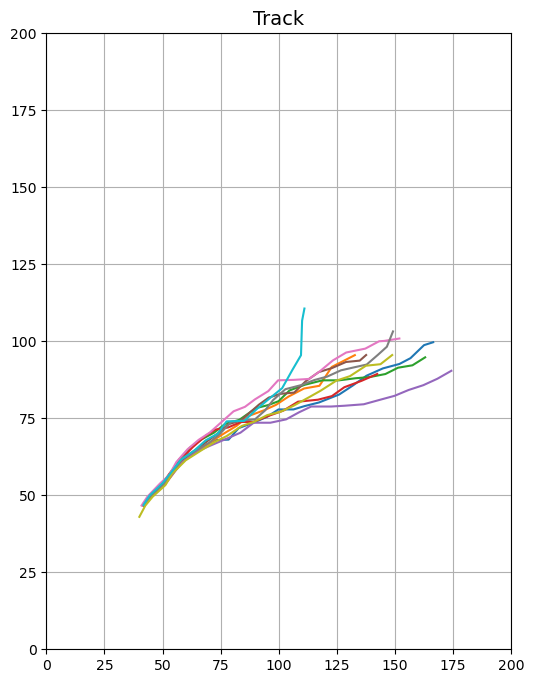

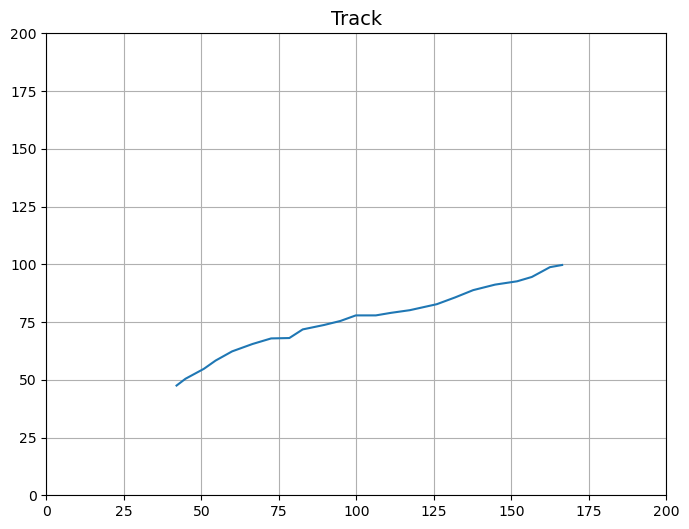

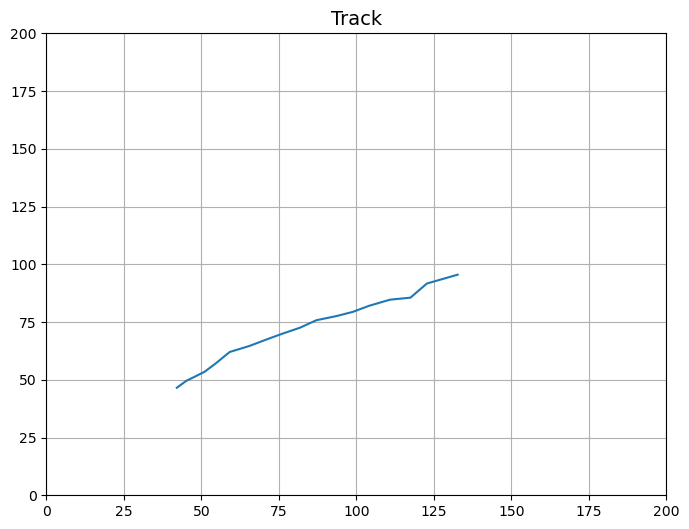

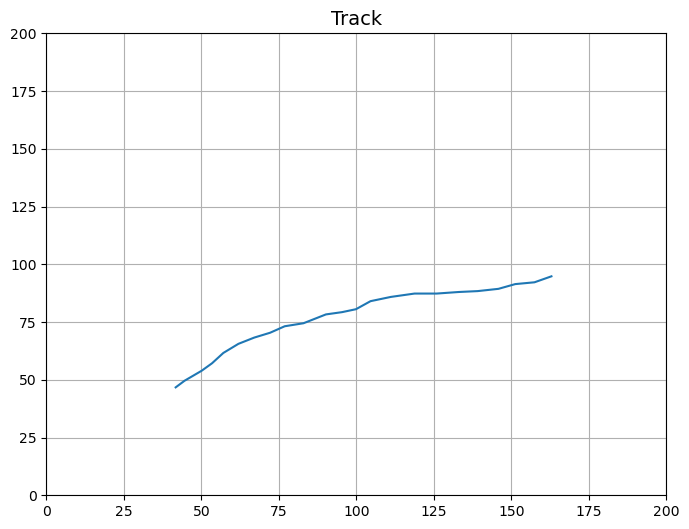

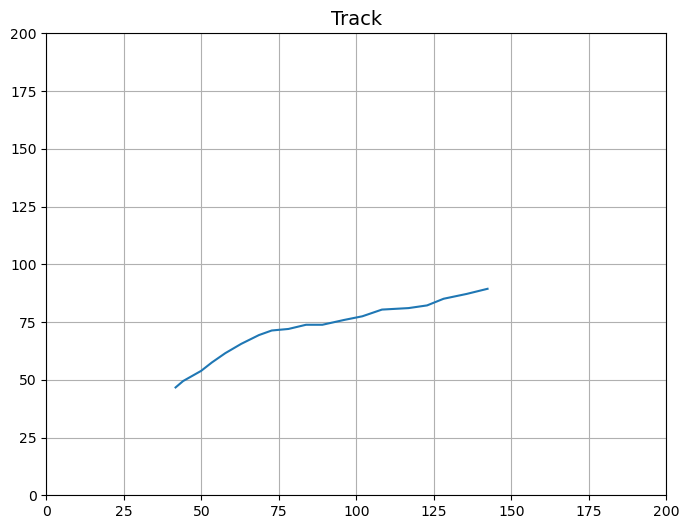

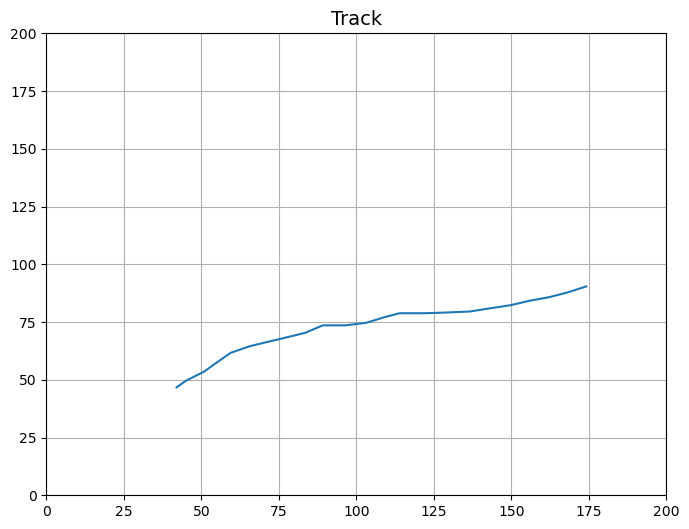

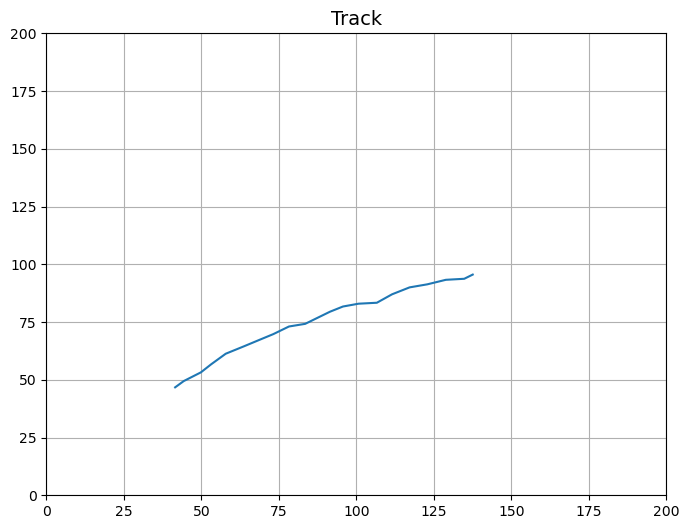

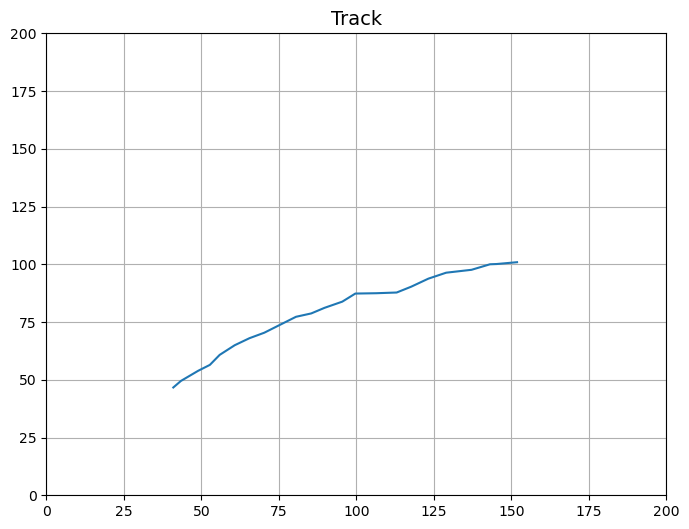

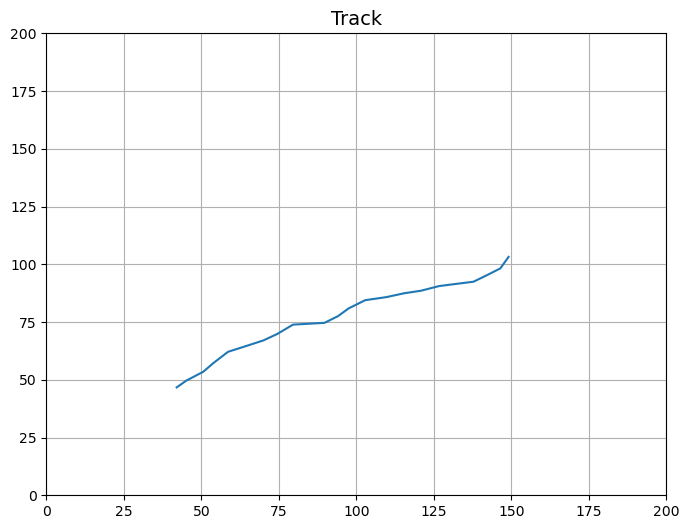

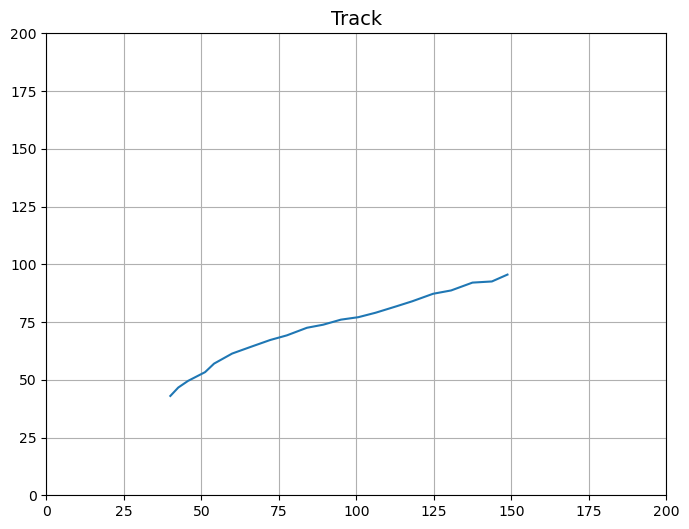

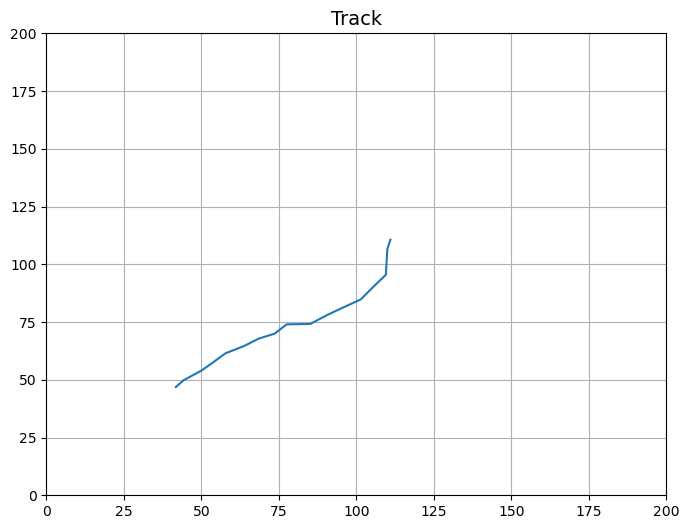

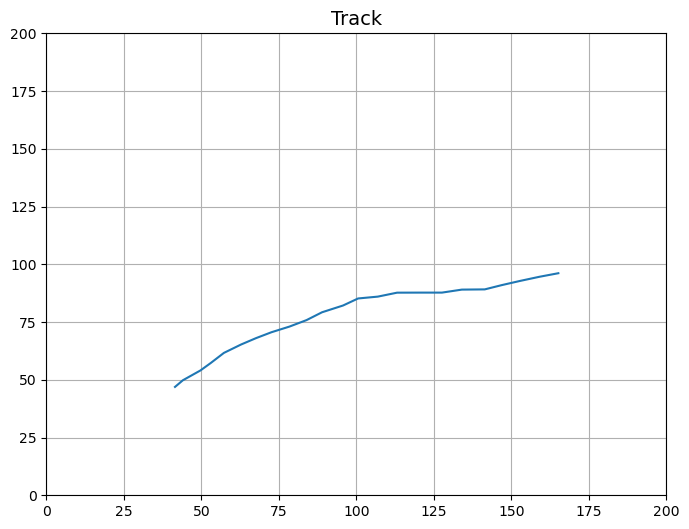

In [6]:
# lunghezza_massima = max(len(row) for row in track)
# track_padded = np.array([row + [np.nan] * (lunghezza_massima - len(row)) for row in track])
# print(np.shape(track))

# Determiniamo la lunghezza massima tra le sottoliste
# lunghezza_massima = max(len(row) for row in track) if track else 0

# Creiamo una nuova lista con padding usando np.nan
# track_padded = np.array([row + [np.nan] * (lunghezza_massima - len(row)) for row in track], dtype=float)

fig = plt.figure(figsize=(6, 8))

ax = fig.add_subplot(1, 1, 1)
ax.set_title("Track", loc="center", fontsize=14)

# MSLP in contours and min max
# c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
# ax.clabel(c1,fmt='%4.1i',fontsize=10)
for i in range(0, 10):  # ciclo sui membri
    # for t in range(0,Nup-1):
    ax.plot(tracks[i, 1, :], tracks[i, 2, :])
ax.set_xlim(0, 200)
ax.set_ylim(0, 200)
plt.grid()
figname = "/glade/u/home/fdemartin/plot/track/"
fig.savefig(figname + "all.png", bbox_inches="tight")

for i in range(0, 11):  # ciclo sui membri
    fig = plt.figure(figsize=(8, 6))

    ax = fig.add_subplot(1, 1, 1)
    ax.set_title("Track", loc="center", fontsize=14)

    # MSLP in contours and min max
    # c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
    # ax.clabel(c1,fmt='%4.1i',fontsize=10)

    # for t in range(0,Nup-1):
    ax.plot(tracks[i, 1, :], tracks[i, 2, :])
    ax.set_xlim(0, 200)
    ax.set_ylim(0, 200)
    plt.grid()
    figname = (
        "/glade/u/home/fdemartin/plot/track/" + str(exp) + "_" + str(i)
    )
    fig.savefig(figname + ".png", bbox_inches="tight")

    data = np.vstack([tracks[i, 1, :], tracks[i, 2, :]])
    df = pd.DataFrame(np.transpose(data), index=time_to_int, columns=["x", "y"])
    df.to_csv(
        "/glade/u/home/fdemartin/SPOUT/tracks/track_"
        + str(exp)
        + "_"
        + str(i)
        + ".csv"
    )

    # df=pd.DataFrame(np.transpose(yup),index=time1, columns=[str(z) for z in range(1, Nup+2)])
    # df.to_csv("/glade/u/home/fdemartin/SPOUT/tracks/yup_"+str(exp)+"_"+str(i)+".csv")
    # print("/glade/u/home/fdemartin/SPOUT/tracks/yup_"+str(exp)+"_"+str(i)+".csv")

In [7]:
radius = 8
uh = np.zeros([11, len(time_to_int)])
uh_mean = np.zeros([11, len(time_to_int)])
wmax = np.zeros([11, len(time_to_int)])
w500_mean = np.zeros([11, len(time_to_int)])
w500 = np.zeros([11, len(time_to_int)])
w700_mean = np.zeros([11, len(time_to_int)])
w700 = np.zeros([11, len(time_to_int)])
w850_mean = np.zeros([11, len(time_to_int)])
w850 = np.zeros([11, len(time_to_int)])
w950_mean = np.zeros([11, len(time_to_int)])
w950 = np.zeros([11, len(time_to_int)])
avo500_mean = np.zeros([11, len(time_to_int)])
avo500 = np.zeros([11, len(time_to_int)])
avo700_mean = np.zeros([11, len(time_to_int)])
avo700 = np.zeros([11, len(time_to_int)])
avo850_mean = np.zeros([11, len(time_to_int)])
avo850 = np.zeros([11, len(time_to_int)])
avo950_mean = np.zeros([11, len(time_to_int)])
theta = np.zeros([11, len(time_to_int)])
theta_mean = np.zeros([11, len(time_to_int)])
avo950 = np.zeros([11, len(time_to_int)])
thetae_mean = np.zeros([11, len(time_to_int)])
thetae = np.zeros([11, len(time_to_int)])

# print(np.shape(wa))
for i in range(0, 11):
    print(i)
    WRF_DIRECTORY = "/glade/derecho/scratch/fdemartin/ens/" + exp + "/" + str(i) + "/"

    os.chdir(WRF_DIRECTORY)
    WRF_FILES = os.listdir()

    _WRF_FILES = [
        os.path.abspath(os.path.expanduser(os.path.join(WRF_DIRECTORY, f)))
        for f in WRF_FILES
    ]

    def single_wrf_file():
        global _WRF_FILES
        return _WRF_FILES[0]

    def multiple_wrf_files():
        global _WRF_FILES
        return _WRF_FILES

    file_paths = (
        multiple_wrf_files()
    )  # Necessary due to single_wrf_file being a function
    # print(file_paths)
    file_paths = [f for f in file_paths if extract_time(f)[0] >= 14]
    file_paths = sorted(file_paths, key=extract_time)
    # print(file_paths)
    wrf_files = [Dataset(f) for f in file_paths]
    # print(wrf_files[:])

    period = len(WRF_FILES)

    # ncfile = Dataset(WRF_DIRECTORY)
    times = to_np(
        getvar(wrf_files, "times", timeidx=ALL_TIMES, meta=False, method="join")
    )
    uh_nc = to_np(getvar(wrf_files, "UP_HELI_MAX", timeidx=ALL_TIMES, method="join"))
    wa_nc = to_np(getvar(wrf_files, "wa", timeidx=ALL_TIMES, method="join"))
    avo_nc = to_np(getvar(wrf_files, "avo", timeidx=ALL_TIMES, method="join"))
    p = to_np(getvar(wrf_files, "pressure", timeidx=ALL_TIMES, method="join"))
    wmax_nc = to_np(getvar(wrf_files, "W_UP_MAX", timeidx=ALL_TIMES, method="join"))
    theta_nc = to_np(getvar(wrf_files, "theta", timeidx=ALL_TIMES, method="join"))
    thetae_nc = to_np(getvar(wrf_files, "theta_e", timeidx=ALL_TIMES, method="join"))

    w950_nc = interplevel(wa_nc, p, 950)
    w850_nc = interplevel(wa_nc, p, 850)
    w700_nc = interplevel(wa_nc, p, 700)
    w500_nc = interplevel(wa_nc, p, 500)

    avo950_nc = interplevel(avo_nc, p, 950)
    avo850_nc = interplevel(avo_nc, p, 850)
    avo700_nc = interplevel(avo_nc, p, 700)
    avo500_nc = interplevel(avo_nc, p, 500)
    # print(np.shape(theta_nc))
    thetae500_nc = interplevel(thetae_nc, p, 500)

    for t in range(0, len(time_to_int)):
        if not np.isnan(tracks[i, 2, t]):
            # print(np.max(var[t+time_to_int[0],:,:]))
            uh[i, t] = np.max(
                uh_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            uh_mean[i, t] = np.mean(
                uh_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            wmax[i, t] = np.max(
                wmax_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            w500[i, t] = np.max(
                w500_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            w500_mean[i, t] = np.mean(
                w500_nc[
                    t + 1,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            w700[i, t] = np.max(
                w700_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            w700_mean[i, t] = np.mean(
                w700_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            w850[i, t] = np.max(
                w850_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            w850_mean[i, t] = np.mean(
                w850_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            w950[i, t] = np.max(
                w950_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            w950_mean[i, t] = np.mean(
                w950_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            avo500[i, t] = np.max(
                avo500_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            avo500_mean[i, t] = np.mean(
                avo500_nc[
                    t + 1,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            avo700[i, t] = np.max(
                avo700_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            avo700_mean[i, t] = np.mean(
                avo700_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            avo850[i, t] = np.max(
                avo850_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            avo850_mean[i, t] = np.mean(
                avo850_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            avo950[i, t] = np.max(
                avo950_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            avo950_mean[i, t] = np.mean(
                avo950_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            theta[i, t] = np.min(
                theta_nc[
                    t,
                    0,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            theta_mean[i, t] = np.mean(
                theta_nc[
                    t,
                    0,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            thetae[i, t] = np.max(
                thetae500_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )
            thetae_mean[i, t] = np.mean(
                thetae500_nc[
                    t,
                    (int(tracks[i, 2, t] - radius)) : (int(tracks[i, 2, t] + radius)),
                    (int(tracks[i, 1, t] - radius)) : (int(tracks[i, 1, t] + radius)),
                ]
            )

            # print(t+time_to_int[0],tracks[i,1,t],tracks[i,2,t],wa[i,t])
df = pd.DataFrame(
    np.transpose(uh), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/uh_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(uh_mean), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/uh_mean_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(wmax), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/wmax_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(w500), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/w500_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(w500_mean), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/w500_mean_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(w700), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/w700_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(w700_mean), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/w700_mean_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(w850), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/w850_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(w850_mean), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/w850_mean_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(w950), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/w950_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(w950_mean), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/w950_mean_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(w950), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/w950_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(avo950), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/avo950_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(avo850), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/avo850_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(avo850_mean), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/avo850_mean_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(avo700), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/avo700_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(avo700_mean), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/avo700_mean_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(avo500), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/avo500_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(avo500_mean), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/avo500_mean_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(theta), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/theta_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(theta_mean), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/theta_mean_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(thetae), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/thetae_" + str(exp) + ".csv")
df = pd.DataFrame(
    np.transpose(thetae_mean), index=time_to_int, columns=[str(z) for z in range(0, 11)]
)
df.to_csv("/glade/u/home/fdemartin/dati/citysize/thetae_mean_" + str(exp) + ".csv")

0
1
2
3
4
5
6
7
8
9
10


NameError: name 'var' is not defined

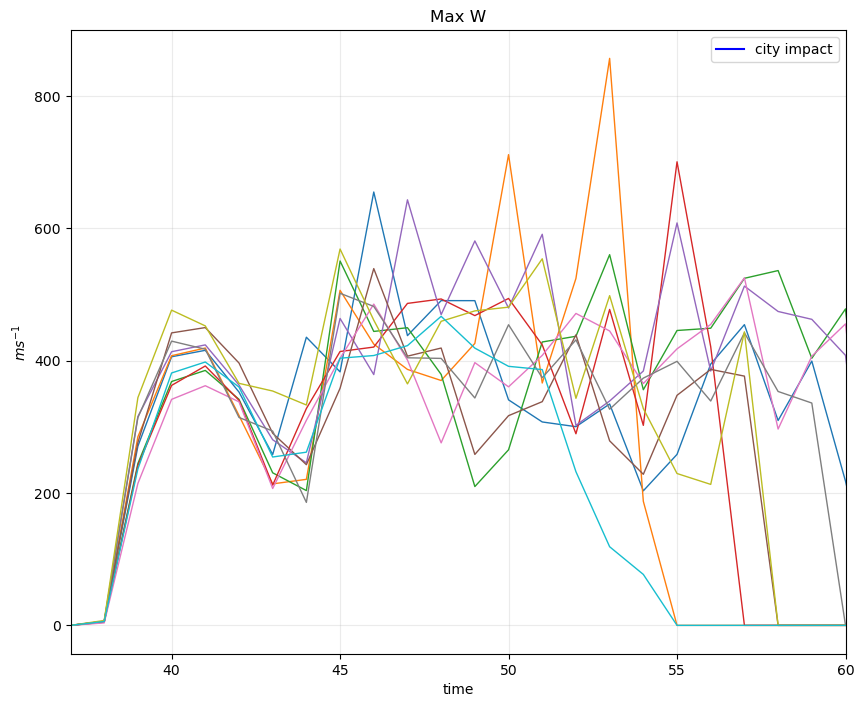

In [8]:
fig = plt.figure(figsize=(10, 8.1))
ax = fig.add_subplot(1, 1, 1)
# ax.plot(time_no,UH[0,:],'r-',linewidth=1, label='control no urban')
# ax.plot(time_no,UH2[0,:],'m-',linewidth=1, label='control 20km')
# ax.plot(time_no,UH3[0,:],'k-',linewidth=1, label='control 10km')
# ax.plot(time_no,UH_mean,'b-',linewidth=3, label='no urban')
# ax.errorbar(time_no, UH_mean, yerr=UH_std, fmt='o', color='b',capsize=5, label="$\sigma$")
# ax.plot(time_no,UH_mean2,'y-',linewidth=3, label='mean 20km')
# ax.errorbar(time_no, UH_mean2, yerr=UH_std2, fmt='o', color='y',capsize=5, label="$\sigma$")
# ax.plot(time_no,UH_mean3,'g-',linewidth=3, label='mean 30km')
# ax.errorbar(time_no, UH_mean3, yerr=UH_std3, fmt='o', color='g',capsize=5, label="$\sigma$")

for i in range(0, 10):
    ax.plot(time_to_int, uh[i, :], linewidth=1)
plt.axvline(x=25.5, color="b", label="city impact")
plt.axvline(x=26.0, color="b")
# ax.set_ylim(0,50)
ax.set_xlim(37, 60)
ax.set_ylabel("$ms^{-1}$")
ax.set_xlabel("time")
ax.legend()
ax.grid(alpha=0.25)
plt.title("Max W")
plt.savefig(
    "/glade/u/home/fdemartin/dati/no_urban/" + var + ".png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0,
)

In [ ]:
for i in range(0,11):
    WRF_DIRECTORY="/glade/derecho/scratch/fdemartin/ens/"+exp+"/"+str(i)+"/"

    os.chdir(WRF_DIRECTORY)
    WRF_FILES = os.listdir()

    _WRF_FILES = [os.path.abspath(os.path.expanduser(
        os.path.join(WRF_DIRECTORY, f))) for f in WRF_FILES]

    def single_wrf_file():
        global _WRF_FILES
        return _WRF_FILES[0]

    def multiple_wrf_files():
        global _WRF_FILES
        return _WRF_FILES
    
    file_paths = multiple_wrf_files() # Necessary due to single_wrf_file being a function
    
    wrf_files = [Dataset(f) for f in file_paths]
    period=len(WRF_FILES)
    
    #ncfile = Dataset(WRF_DIRECTORY)
    times = to_np(getvar(wrf_files,'times',timeidx=ALL_TIMES, meta=False,method="join"))
    var=to_np(getvar(wrf_files,"wa",timeidx=ALL_TIMES,method="join"))
    
    for t in range(time_to_int(0),60):    
          wa=var[
#p_join = getvar(wrflist, "P", timeidx=ALL_TIMES, method="join")
var=to_np(getvar(wrf_files,"wa",timeidx=ALL_TIMES,method="join"))
#uh=to_np(getvar(ncfile,"UP_HELI_MAX",timeidx=ALL_TIMES,method="join"))
var_lu=to_np(getvar(wrf_files,"LU_INDEX",timeidx=ALL_TIMES,method="join"))

WRF_DIRECTORY=dir+"control_wrfout_d01_2023-05-31_08:00:00"
ncfile = Dataset(WRF_DIRECTORY)
times = getvar(ncfile,'times',timeidx=ALL_TIMES, meta=False)
time_wrf1=np.linspace(start_time,start_time+delta_time*(period-1),period)*units.hour
t_point1=np.zeros([period])
td_point1=np.zeros([period])
#city
var=to_np(getvar(ncfile,"UP_HELI_MAX",timeidx=ALL_TIMES))
uh_max_c=np.amax(var[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
uh_mean_c=np.mean(var[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))

wmax=to_np(getvar(ncfile,"W_UP_MAX",timeidx=ALL_TIMES))
wmax_max_c=np.amax(wmax[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
wmax_mean_c=np.amax(wmax[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))

wmin=to_np(getvar(ncfile,"W_DN_MAX",timeidx=ALL_TIMES))
wmin_min_c=np.amin(wmin[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
wmin_mean_c=np.amin(wmin[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))

wmean=to_np(getvar(ncfile,"W_MEAN",timeidx=ALL_TIMES))
wmean_max_c=np.max(wmean[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
wmean_mean_c=np.max(wmean[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))

wa=to_np(getvar(ncfile,"wa",timeidx=ALL_TIMES))
p=to_np(getvar(ncfile,"pressure",timeidx=ALL_TIMES))
w950 = interplevel(wa, p, 950)
w950_max_c=np.amax(w950[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
w950_mean_c=np.mean(w950[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
w850 = interplevel(wa, p, 850)
w850_max_c=np.amax(w850[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
w850_mean_c=np.amax(w850[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
w700 = interplevel(wa, p, 700)
w700_max_c=np.amax(w700[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
w700_mean_c=np.amax(w700[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
w500 = interplevel(wa, p, 500)
w500_max_c=np.amax(w500[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
w500_mean_c=np.amax(w500[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))

# #upwind
# uh=to_np(getvar(ncfile,"UP_HELI_MAX",timeidx=ALL_TIMES))
# uh_max_u=np.amax(var[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# uh_mean_u=np.mean(var[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))

# wmax=to_np(getvar(ncfile,"W_UP_MAX",timeidx=ALL_TIMES))
# wmax_max_u=np.amax(wmax[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# wmax_mean_u=np.amax(wmax[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))

# wmin=to_np(getvar(ncfile,"W_DN_MAX",timeidx=ALL_TIMES))
# wmin_min_u=np.amin(wmin[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# wmin_mean_u=np.amin(wmin[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))

# wmean=to_np(getvar(ncfile,"W_MEAN",timeidx=ALL_TIMES))
# wmean_max_u=np.max(wmean[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# wmean_mean_u=np.max(wmean[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))

# w950 = interplevel(wa, p, 950)
# w950_max_u=np.amax(w950[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# w950_mean_u=np.mean(w950[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# w850 = interplevel(wa, p, 850)
# w850_max_u=np.amax(w850[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# w850_mean_u=np.amax(w850[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# w700 = interplevel(wa, p, 700)
# w700_max_u=np.amax(w700[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# w700_mean_u=np.amax(w700[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# w500 = interplevel(wa, p, 500)
# w500_max_u=np.amax(w500[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# w500_mean_u=np.amax(w500[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))

# #downwind
# uh=to_np(getvar(ncfile,"UP_HELI_MAX",timeidx=ALL_TIMES))
# uh_max_d=np.amax(var[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# uh_mean_d=np.mean(var[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))

# wmax=to_np(getvar(ncfile,"W_UP_MAX",timeidx=ALL_TIMES))
# wmax_max_d=np.amax(wmax[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# wmax_mean_d=np.amax(wmax[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))

# wmin=to_np(getvar(ncfile,"W_DN_MAX",timeidx=ALL_TIMES))
# wmin_min_d=np.amin(wmin[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# wmin_mean_d=np.amin(wmin[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))

# wmean=to_np(getvar(ncfile,"W_MEAN",timeidx=ALL_TIMES))
# wmean_max_d=np.max(wmean[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# wmean_mean_d=np.max(wmean[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))

# w950 = interplevel(wa, p, 950)
# w950_max_d=np.amax(w950[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# w950_mean_d=np.mean(w950[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# w850 = interplevel(wa, p, 850)
# w850_max_d=np.amax(w850[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# w850_mean_d=np.amax(w850[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# w700 = interplevel(wa, p, 700)
# w700_max_d=np.amax(w700[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# w700_mean_d=np.amax(w700[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# w500 = interplevel(wa, p, 500)
# w500_max_d=np.amax(w500[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# w500_mean_d=np.amax(w500[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))

# data_max=np.vstack([uh_mean_c,wmax_mean_c,wmin_mean_c,wmean_mean_c,uh_mean_u,wmax_mean_u,wmin_mean_u,wmean_mean_u,uh_mean_d,wmax_mean_d,wmin_mean_d,wmean_mean_d,w950_max_c,w850_max_c,w700_max_c,w500_max_c,w950_max_u,w850_max_u,w700_max_u,w500_max_u,w950_max_d,w850_max_d,w700_max_d,w500_max_d])#,w850_max,w700_max,w500_max,s950,s850,s700,s500])#avo950_max,avo850_max,avo700_max,avo500_max])
# data_t=np.transpose(data_max)
# df=pd.DataFrame(data_t,index=time_wrf1, columns=['UH C','WMAX C','WMIN C','WMEAN C','UH U','WMAX U','WMIN U','WMEAN U','UH D','WMAX D','WMIN D','WMEAN D', 'WMAX950c','WMAX850c','WMAX700c','WMAX500c','WMAX950u','WMAX850u','WMAX700u','WMAX500u','WMAX950d','WMAX850d','WMAX700d','WMAX500d'])#'W950','W850','W700','W500','S950','S850','S700','S500'])#,'AVO950','AVO850','AVO700','AVO500'])
# df.to_csv("/glade/u/home/fdemartin/dati/no_urban/"+exp+"_control_max.csv")

# data_max=np.vstack([uh_max_c,wmax_max_c,wmin_min_c,wmean_max_c,uh_max_u,wmax_max_u,wmin_min_u,wmean_max_u,uh_max_d,wmax_max_d,wmin_min_d,wmean_mean_d,w950_mean_c,w850_mean_c,w700_mean_c,w500_mean_c,w950_mean_u,w850_mean_u,w700_mean_u,w500_mean_u,w950_mean_d,w850_mean_d,w700_mean_d,w500_mean_d])#,w850_max,w700_max,w500_max,s950,s850,s700,s500])#avo950_max,avo850_max,avo700_max,avo500_max])
# data_t=np.transpose(data_max)
# df=pd.DataFrame(data_t,index=time_wrf1, columns=['UH C','WMAX C','WMIN C','WMEAN C','UH U','WMAX U','WMIN U','WMEAN U','UH D','WMAX D','WMIN D','WMEAN D','WMAX950c','WMAX850c','WMAX700c','WMAX500c','WMAX950u','WMAX850u','WMAX700u','WMAX500u','WMAX950d','WMAX850d','WMAX700d','WMAX500d'])#'W950','W850','W700','W500','S950','S850','S700','S500'])#,'AVO950','AVO850','AVO700','AVO500'])
# df.to_csv("/glade/u/home/fdemartin/dati/no_urban/"+exp+"_control_max.csv")
# 0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))

data_max=np.vstack([uh_mean_c,wmax_mean_c,wmin_mean_c,wmean_mean_c,w950_max_c,w850_max_c,w700_max_c,w500_max_c])#,w850_max,w700_max,w500_max,s950,s850,s700,s500])#avo950_max,avo850_max,avo700_max,avo500_max])
data_t=np.transpose(data_max)
df=pd.DataFrame(data_t,index=time_wrf1, columns=['UH C','WMAX C','WMIN C','WMEAN C', 'WMAX950c','WMAX850c','WMAX700c','WMAX500c'])#'W950','W850','W700','W500','S950','S850','S700','S500'])#,'AVO950','AVO850','AVO700','AVO500'])
df.to_csv("/glade/u/home/fdemartin/dati/no_urban/"+exp+"_control_max.csv")

data_max=np.vstack([uh_max_c,wmax_max_c,wmin_min_c,wmean_max_c,w950_mean_c,w850_mean_c,w700_mean_c,w500_mean_c])#,w850_max,w700_max,w500_max,s950,s850,s700,s500])#avo950_max,avo850_max,avo700_max,avo500_max])
data_t=np.transpose(data_max)
df=pd.DataFrame(data_t,index=time_wrf1, columns=['UH C','WMAX C','WMIN C','WMEAN C','WMAX950c','WMAX850c','WMAX700c','WMAX500c'])#'W950','W850','W700','W500','S950','S850','S700','S500'])#,'AVO950','AVO850','AVO700','AVO500'])
df.to_csv("/glade/u/home/fdemartin/dati/no_urban/"+exp+"_control_max.csv")

In [ ]:
WRF_DIRECTORY = dir + "control_wrfout_d01_2023-05-31_08:00:00"
ncfile = Dataset(WRF_DIRECTORY)
times = getvar(ncfile, "times", timeidx=ALL_TIMES, meta=False)
time_wrf1 = (
    np.linspace(start_time, start_time + delta_time * (period - 1), period) * units.hour
)
t_point1 = np.zeros([period])
td_point1 = np.zeros([period])
# city
var = to_np(getvar(ncfile, "UP_HELI_MAX", timeidx=ALL_TIMES))
uh_max_c = np.amax(var[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2))
uh_mean_c = np.mean(var[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2))

wmax = to_np(getvar(ncfile, "W_UP_MAX", timeidx=ALL_TIMES))
wmax_max_c = np.amax(wmax[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2))
wmax_mean_c = np.amax(
    wmax[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
)

wmin = to_np(getvar(ncfile, "W_DN_MAX", timeidx=ALL_TIMES))
wmin_min_c = np.amin(wmin[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2))
wmin_mean_c = np.amin(
    wmin[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
)

wmean = to_np(getvar(ncfile, "W_MEAN", timeidx=ALL_TIMES))
wmean_max_c = np.max(
    wmean[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
)
wmean_mean_c = np.max(
    wmean[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
)

wa = to_np(getvar(ncfile, "wa", timeidx=ALL_TIMES))
p = to_np(getvar(ncfile, "pressure", timeidx=ALL_TIMES))
w950 = interplevel(wa, p, 950)
w950_max_c = np.amax(w950[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2))
w950_mean_c = np.mean(
    w950[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
)
w850 = interplevel(wa, p, 850)
w850_max_c = np.amax(w850[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2))
w850_mean_c = np.amax(
    w850[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
)
w700 = interplevel(wa, p, 700)
w700_max_c = np.amax(w700[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2))
w700_mean_c = np.amax(
    w700[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
)
w500 = interplevel(wa, p, 500)
w500_max_c = np.amax(w500[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2))
w500_mean_c = np.amax(
    w500[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
)

# #upwind
# uh=to_np(getvar(ncfile,"UP_HELI_MAX",timeidx=ALL_TIMES))
# uh_max_u=np.amax(var[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# uh_mean_u=np.mean(var[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))

# wmax=to_np(getvar(ncfile,"W_UP_MAX",timeidx=ALL_TIMES))
# wmax_max_u=np.amax(wmax[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# wmax_mean_u=np.amax(wmax[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))

# wmin=to_np(getvar(ncfile,"W_DN_MAX",timeidx=ALL_TIMES))
# wmin_min_u=np.amin(wmin[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# wmin_mean_u=np.amin(wmin[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))

# wmean=to_np(getvar(ncfile,"W_MEAN",timeidx=ALL_TIMES))
# wmean_max_u=np.max(wmean[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# wmean_mean_u=np.max(wmean[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))

# w950 = interplevel(wa, p, 950)
# w950_max_u=np.amax(w950[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# w950_mean_u=np.mean(w950[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# w850 = interplevel(wa, p, 850)
# w850_max_u=np.amax(w850[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# w850_mean_u=np.amax(w850[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# w700 = interplevel(wa, p, 700)
# w700_max_u=np.amax(w700[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# w700_mean_u=np.amax(w700[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# w500 = interplevel(wa, p, 500)
# w500_max_u=np.amax(w500[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
# w500_mean_u=np.amax(w500[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))

# #downwind
# uh=to_np(getvar(ncfile,"UP_HELI_MAX",timeidx=ALL_TIMES))
# uh_max_d=np.amax(var[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# uh_mean_d=np.mean(var[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))

# wmax=to_np(getvar(ncfile,"W_UP_MAX",timeidx=ALL_TIMES))
# wmax_max_d=np.amax(wmax[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# wmax_mean_d=np.amax(wmax[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))

# wmin=to_np(getvar(ncfile,"W_DN_MAX",timeidx=ALL_TIMES))
# wmin_min_d=np.amin(wmin[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# wmin_mean_d=np.amin(wmin[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))

# wmean=to_np(getvar(ncfile,"W_MEAN",timeidx=ALL_TIMES))
# wmean_max_d=np.max(wmean[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# wmean_mean_d=np.max(wmean[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))

# w950 = interplevel(wa, p, 950)
# w950_max_d=np.amax(w950[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# w950_mean_d=np.mean(w950[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# w850 = interplevel(wa, p, 850)
# w850_max_d=np.amax(w850[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# w850_mean_d=np.amax(w850[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# w700 = interplevel(wa, p, 700)
# w700_max_d=np.amax(w700[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# w700_mean_d=np.amax(w700[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# w500 = interplevel(wa, p, 500)
# w500_max_d=np.amax(w500[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
# w500_mean_d=np.amax(w500[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))

# data_max=np.vstack([uh_mean_c,wmax_mean_c,wmin_mean_c,wmean_mean_c,uh_mean_u,wmax_mean_u,wmin_mean_u,wmean_mean_u,uh_mean_d,wmax_mean_d,wmin_mean_d,wmean_mean_d,w950_max_c,w850_max_c,w700_max_c,w500_max_c,w950_max_u,w850_max_u,w700_max_u,w500_max_u,w950_max_d,w850_max_d,w700_max_d,w500_max_d])#,w850_max,w700_max,w500_max,s950,s850,s700,s500])#avo950_max,avo850_max,avo700_max,avo500_max])
# data_t=np.transpose(data_max)
# df=pd.DataFrame(data_t,index=time_wrf1, columns=['UH C','WMAX C','WMIN C','WMEAN C','UH U','WMAX U','WMIN U','WMEAN U','UH D','WMAX D','WMIN D','WMEAN D', 'WMAX950c','WMAX850c','WMAX700c','WMAX500c','WMAX950u','WMAX850u','WMAX700u','WMAX500u','WMAX950d','WMAX850d','WMAX700d','WMAX500d'])#'W950','W850','W700','W500','S950','S850','S700','S500'])#,'AVO950','AVO850','AVO700','AVO500'])
# df.to_csv("/glade/u/home/fdemartin/dati/no_urban/"+exp+"_control_max.csv")

# data_max=np.vstack([uh_max_c,wmax_max_c,wmin_min_c,wmean_max_c,uh_max_u,wmax_max_u,wmin_min_u,wmean_max_u,uh_max_d,wmax_max_d,wmin_min_d,wmean_mean_d,w950_mean_c,w850_mean_c,w700_mean_c,w500_mean_c,w950_mean_u,w850_mean_u,w700_mean_u,w500_mean_u,w950_mean_d,w850_mean_d,w700_mean_d,w500_mean_d])#,w850_max,w700_max,w500_max,s950,s850,s700,s500])#avo950_max,avo850_max,avo700_max,avo500_max])
# data_t=np.transpose(data_max)
# df=pd.DataFrame(data_t,index=time_wrf1, columns=['UH C','WMAX C','WMIN C','WMEAN C','UH U','WMAX U','WMIN U','WMEAN U','UH D','WMAX D','WMIN D','WMEAN D','WMAX950c','WMAX850c','WMAX700c','WMAX500c','WMAX950u','WMAX850u','WMAX700u','WMAX500u','WMAX950d','WMAX850d','WMAX700d','WMAX500d'])#'W950','W850','W700','W500','S950','S850','S700','S500'])#,'AVO950','AVO850','AVO700','AVO500'])
# df.to_csv("/glade/u/home/fdemartin/dati/no_urban/"+exp+"_control_max.csv")
# 0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))

data_max = np.vstack(
    [
        uh_mean_c,
        wmax_mean_c,
        wmin_mean_c,
        wmean_mean_c,
        w950_max_c,
        w850_max_c,
        w700_max_c,
        w500_max_c,
    ]
)  # ,w850_max,w700_max,w500_max,s950,s850,s700,s500])#avo950_max,avo850_max,avo700_max,avo500_max])
data_t = np.transpose(data_max)
df = pd.DataFrame(
    data_t,
    index=time_wrf1,
    columns=[
        "UH C",
        "WMAX C",
        "WMIN C",
        "WMEAN C",
        "WMAX950c",
        "WMAX850c",
        "WMAX700c",
        "WMAX500c",
    ],
)  #'W950','W850','W700','W500','S950','S850','S700','S500'])#,'AVO950','AVO850','AVO700','AVO500'])
df.to_csv("/glade/u/home/fdemartin/dati/no_urban/" + exp + "_control_max.csv")

data_max = np.vstack(
    [
        uh_max_c,
        wmax_max_c,
        wmin_min_c,
        wmean_max_c,
        w950_mean_c,
        w850_mean_c,
        w700_mean_c,
        w500_mean_c,
    ]
)  # ,w850_max,w700_max,w500_max,s950,s850,s700,s500])#avo950_max,avo850_max,avo700_max,avo500_max])
data_t = np.transpose(data_max)
df = pd.DataFrame(
    data_t,
    index=time_wrf1,
    columns=[
        "UH C",
        "WMAX C",
        "WMIN C",
        "WMEAN C",
        "WMAX950c",
        "WMAX850c",
        "WMAX700c",
        "WMAX500c",
    ],
)  #'W950','W850','W700','W500','S950','S850','S700','S500'])#,'AVO950','AVO850','AVO700','AVO500'])
df.to_csv("/glade/u/home/fdemartin/dati/no_urban/" + exp + "_control_max.csv")

In [ ]:
for i in range(0, 10):
    WRF_DIRECTORY = dir + str(i) + "_wrfout_d01_2023-05-31_08:00:00"
    ncfile = Dataset(WRF_DIRECTORY)
    times = getvar(ncfile, "times", timeidx=ALL_TIMES, meta=False)
    time_wrf1 = (
        np.linspace(start_time, start_time + delta_time * (period - 1), period)
        * units.hour
    )
    t_point1 = np.zeros([period])
    td_point1 = np.zeros([period])

    # city
    var = to_np(getvar(ncfile, "UP_HELI_MAX", timeidx=ALL_TIMES))
    uh_max_c = np.amax(
        var[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
    )
    uh_mean_c = np.mean(
        var[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
    )

    wmax = to_np(getvar(ncfile, "W_UP_MAX", timeidx=ALL_TIMES))
    wmax_max_c = np.amax(
        wmax[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
    )
    wmax_mean_c = np.amax(
        wmax[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
    )

    wmin = to_np(getvar(ncfile, "W_DN_MAX", timeidx=ALL_TIMES))
    wmin_min_c = np.amin(
        wmin[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
    )
    wmin_mean_c = np.amin(
        wmin[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
    )

    wmean = to_np(getvar(ncfile, "W_MEAN", timeidx=ALL_TIMES))
    wmean_max_c = np.max(
        wmean[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
    )
    wmean_mean_c = np.max(
        wmean[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
    )

    wa = to_np(getvar(ncfile, "wa", timeidx=ALL_TIMES))
    p = to_np(getvar(ncfile, "pressure", timeidx=ALL_TIMES))
    w950 = interplevel(wa, p, 950)
    w950_max_c = np.amax(
        w950[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
    )
    w950_mean_c = np.mean(
        w950[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
    )
    w850 = interplevel(wa, p, 850)
    w850_max_c = np.amax(
        w850[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
    )
    w850_mean_c = np.amax(
        w850[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
    )
    w700 = interplevel(wa, p, 700)
    w700_max_c = np.amax(
        w700[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
    )
    w700_mean_c = np.amax(
        w700[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
    )
    w500 = interplevel(wa, p, 500)
    w500_max_c = np.amax(
        w500[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
    )
    w500_mean_c = np.amax(
        w500[:, y_city[0] : y_city[1], x_city[0] : x_city[1]], axis=(1, 2)
    )

    # avo=to_np(getvar(ncfile,'avo',timeidx=ALL_TIMES))
    # w950 = interplevel(avo, p, 950)
    # avo950_max_c=np.amax(w950[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
    # avo950_mean_c=np.mean(w950[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
    # w850 = interplevel(avo, p, 850)
    # avo850_max_c=np.amax(w850[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
    # avo850_mean_c=np.amax(w850[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
    # w700 = interplevel(avo, p, 700)
    # avo700_max_c=np.amax(w700[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
    # avo700_mean_c=np.amax(w700[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
    # w500 = interplevel(avo, p, 500)
    # avo500_max_c=np.amax(w500[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
    # avo500_mean_c=np.amax(w500[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))

    # upwind
    # uh=to_np(getvar(ncfile,"UP_HELI_MAX",timeidx=ALL_TIMES))
    # uh_max_u=np.amax(var[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
    # uh_mean_u=np.mean(var[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))

    # wmax=to_np(getvar(ncfile,"W_UP_MAX",timeidx=ALL_TIMES))
    # wmax_max_u=np.amax(wmax[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
    # wmax_mean_u=np.amax(wmax[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))

    # wmin=to_np(getvar(ncfile,"W_DN_MAX",timeidx=ALL_TIMES))
    # wmin_min_u=np.amin(wmin[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
    # wmin_mean_u=np.amin(wmin[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))

    # wmean=to_np(getvar(ncfile,"W_MEAN",timeidx=ALL_TIMES))
    # wmean_max_u=np.max(wmean[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
    # wmean_mean_u=np.max(wmean[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))

    # #wa=to_np(getvar(ncfile,"wa",timeidx=ALL_TIMES))
    # #p=to_np(getvar(ncfile,"pressure",timeidx=ALL_TIMES))
    # w950 = interplevel(wa, p, 950)
    # w950_max_u=np.amax(w950[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
    # w950_mean_u=np.mean(w950[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
    # w850 = interplevel(wa, p, 850)
    # w850_max_u=np.amax(w850[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
    # w850_mean_u=np.amax(w850[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
    # w700 = interplevel(wa, p, 700)
    # w700_max_u=np.amax(w700[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
    # w700_mean_u=np.amax(w700[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
    # w500 = interplevel(wa, p, 500)
    # w500_max_u=np.amax(w500[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))
    # w500_mean_u=np.amax(w500[:,y_upwind[0]:y_upwind[1],x_upwind[0]:x_upwind[1]],axis=(1,2))

    # #downwind
    # uh=to_np(getvar(ncfile,"UP_HELI_MAX",timeidx=ALL_TIMES))
    # uh_max_d=np.amax(var[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
    # uh_mean_d=np.mean(var[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))

    # wmax=to_np(getvar(ncfile,"W_UP_MAX",timeidx=ALL_TIMES))
    # wmax_max_d=np.amax(wmax[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
    # wmax_mean_d=np.amax(wmax[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))

    # wmin=to_np(getvar(ncfile,"W_DN_MAX",timeidx=ALL_TIMES))
    # wmin_min_d=np.amin(wmin[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
    # wmin_mean_d=np.amin(wmin[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))

    # wmean=to_np(getvar(ncfile,"W_MEAN",timeidx=ALL_TIMES))
    # wmean_max_d=np.max(wmean[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
    # wmean_mean_d=np.max(wmean[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))

    # w950 = interplevel(wa, p, 950)
    # w950_max_d=np.amax(w950[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
    # w950_mean_d=np.mean(w950[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
    # w850 = interplevel(wa, p, 850)
    # w850_max_d=np.amax(w850[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
    # w850_mean_d=np.amax(w850[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
    # w700 = interplevel(wa, p, 700)
    # w700_max_d=np.amax(w700[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
    # w700_mean_d=np.amax(w700[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
    # w500 = interplevel(wa, p, 500)
    # w500_max_d=np.amax(w500[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))
    # w500_mean_d=np.amax(w500[:,y_downwind[0]:y_downwind[1],x_downwind[0]:x_downwind[1]],axis=(1,2))

    # data_max=np.vstack([uh_mean_c,wmax_mean_c,wmin_mean_c,wmean_mean_c,uh_mean_u,wmax_mean_u,wmin_mean_u,wmean_mean_u,uh_mean_d,wmax_mean_d,wmin_mean_d,wmean_mean_d,w950_max_c,w850_max_c,w700_max_c,w500_max_c,w950_max_u,w850_max_u,w700_max_u,w500_max_u,w950_max_d,w850_max_d,w700_max_d,w500_max_d])#,w850_max,w700_max,w500_max,s950,s850,s700,s500])#avo950_max,avo850_max,avo700_max,avo500_max])
    # data_t=np.transpose(data_max)
    # df=pd.DataFrame(data_t,index=time_wrf1, columns=['UH C','WMAX C','WMIN C','WMEAN C','UH U','WMAX U','WMIN U','WMEAN U','UH D','WMAX D','WMIN D','WMEAN D', 'WMAX950c','WMAX850c','WMAX700c','WMAX500c','WMAX950u','WMAX850u','WMAX700u','WMAX500u','WMAX950d','WMAX850d','WMAX700d','WMAX500d'])#'W950','W850','W700','W500','S950','S850','S700','S500'])#,'AVO950','AVO850','AVO700','AVO500'])
    # df.to_csv("/glade/u/home/fdemartin/dati/no_urban/"+exp+"_"+str(i)+"_mean.csv")
    # print("/glade/u/home/fdemartin/dati/no_urban/"+exp+"_"+str(i)+"_mean.csv")

    # data_max=np.vstack([uh_max_c,wmax_max_c,wmin_min_c,wmean_max_c,uh_max_u,wmax_max_u,wmin_min_u,wmean_max_u,uh_max_d,wmax_max_d,wmin_min_d,wmean_mean_d,w950_mean_c,w850_mean_c,w700_mean_c,w500_mean_c,w950_mean_u,w850_mean_u,w700_mean_u,w500_mean_u,w950_mean_d,w850_mean_d,w700_mean_d,w500_mean_d])#,w850_max,w700_max,w500_max,s950,s850,s700,s500])#avo950_max,avo850_max,avo700_max,avo500_max])
    # data_t=np.transpose(data_max)
    # df=pd.DataFrame(data_t,index=time_wrf1, columns=['UH C','WMAX C','WMIN C','WMEAN C','UH U','WMAX U','WMIN U','WMEAN U','UH D','WMAX D','WMIN D','WMEAN D','WMAX950c','WMAX850c','WMAX700c','WMAX500c','WMAX950u','WMAX850u','WMAX700u','WMAX500u','WMAX950d','WMAX850d','WMAX700d','WMAX500d'])#'W950','W850','W700','W500','S950','S850','S700','S500'])#,'AVO950','AVO850','AVO700','AVO500'])
    # df.to_csv("/glade/u/home/fdemartin/dati/no_urban/"+exp+"_"+str(i)+"_max.csv")
    # print("/glade/u/home/fdemartin/dati/no_urban/"+exp+"_"+str(i)+"_max.csv")

    data_max = np.vstack(
        [
            uh_mean_c,
            wmax_mean_c,
            wmin_mean_c,
            wmean_mean_c,
            w950_max_c,
            w850_max_c,
            w700_max_c,
            w500_max_c,
        ]
    )  # ,w850_max,w700_max,w500_max,s950,s850,s700,s500])#avo950_max,avo850_max,avo700_max,avo500_max])
    data_t = np.transpose(data_max)
    df = pd.DataFrame(
        data_t,
        index=time_wrf1,
        columns=[
            "UH C",
            "WMAX C",
            "WMIN C",
            "WMEAN C",
            "WMAX950c",
            "WMAX850c",
            "WMAX700c",
            "WMAX500c",
        ],
    )  #'W950','W850','W700','W500','S950','S850','S700','S500'])#,'AVO950','AVO850','AVO700','AVO500'])
    df.to_csv("/glade/u/home/fdemartin/dati/no_urban/" + exp + "_control_max.csv")

    data_max = np.vstack(
        [
            uh_max_c,
            wmax_max_c,
            wmin_min_c,
            wmean_max_c,
            w950_mean_c,
            w850_mean_c,
            w700_mean_c,
            w500_mean_c,
        ]
    )  # ,w850_max,w700_max,w500_max,s950,s850,s700,s500])#avo950_max,avo850_max,avo700_max,avo500_max])
    data_t = np.transpose(data_max)
    df = pd.DataFrame(
        data_t,
        index=time_wrf1,
        columns=[
            "UH C",
            "WMAX C",
            "WMIN C",
            "WMEAN C",
            "WMAX950c",
            "WMAX850c",
            "WMAX700c",
            "WMAX500c",
        ],
    )  #'W950','W850','W700','W500','S950','S850','S700','S500'])#,'AVO950','AVO850','AVO700','AVO500'])
    df.to_csv("/glade/u/home/fdemartin/dati/no_urban/" + exp + "_control_max.csv")

In [ ]:
# p = getvar(ncfile, "pressure",timeidx=ALL_TIMES)
# wa = getvar(ncfile, "wa", units="ms-1",timeidx=ALL_TIMES)
# #print(wa)
# ua = getvar(ncfile, "ua", units="ms-1",timeidx=ALL_TIMES)
# va = getvar(ncfile, "va", units="ms-1",timeidx=ALL_TIMES)
# avo = mpcalc.vorticity(to_np(ua)*units('m/s'),to_np(va)*units('m/s'),dx=500*units.m,dy=500*units.m)
# print(avo)

In [ ]:
# w950 = interplevel(wa, p, 950)
# w950_max_max=np.amax(w950[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
# w950_mean=np.amax(w950[:,y_city[0]:y_city[1],x_city[0]:x_city[1]],axis=(1,2))
# w850 = interplevel(wa, p, 850)
# w850_max=np.amax(w850[:,y_interval[0]:y_interval[1],x_interval[0]:x_interval[1]],axis=(1,2))
# w700 = interplevel(wa, p, 700)
# w700_max=np.amax(w700[:,y_interval[0]:y_interval[1],x_interval[0]:x_interval[1]],axis=(1,2))
# w500 = interplevel(wa, p, 500)
# w500_max=np.amax(w500[:,y_interval[0]:y_interval[1],x_interval[0]:x_interval[1]],axis=(1,2))

In [ ]:
# s950=np.zeros(period)
# s850=np.zeros(period)
# s700=np.zeros(period)
# s500=np.zeros(period)

In [ ]:
# for t in range(40,period):
#     for i in range(x_interval[0],x_interval[1]):
#         for j in range(y_interval[0],y_interval[1]):
#             if w950[t,j,i]>threshold_950:
#                 s950[t]=s950[t]+1
#             if w850[t,j,i]>threshold_850:
#                 s850[t]=s850[t]+1
#             if w700[t,j,i]>threshold_700:
#                 s700[t]=s700[t]+1
#             if w500[t,j,i]>threshold_500:
#                 s500[t]=s500[t]+1